# ViT-Base — transfer-learning strategies
Same data, splits, preprocessing, hyper-parameters (`configs/base.yaml`), training loop and MLflow tracking as
`02_efficientnetv2_strategies_classification.ipynb` / `03_convnextv2_strategies_classification.ipynb`;
only the backbone changes.

| strategy | trainable |
|---|---|
| `feature_extraction` | classifier head only |
| `partial` | head + final `norm` + last `PARTIAL_BLOCKS` of 12 transformer blocks |
| `full` | everything (incl. patch embedding, `cls_token`, `pos_embed`) |

ViT blocks are all the same size, so `PARTIAL_BLOCKS = 6` (half the depth) mirrors ConvNeXt's
"last 2 of 4 stages" by depth.

In [1]:
import sys, json, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import yaml, timm, torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,roc_auc_score, confusion_matrix)
from tqdm.auto import tqdm

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.datasets import Preprocessor, PlantDataset      
import mlflow
from src import tracking
tracking.setup(PROJECT_ROOT, "plant-disease-transfer-learning")  

In [3]:
CFG       = yaml.safe_load((PROJECT_ROOT / "configs" / "base.yaml").read_text())
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
META      = json.loads((SPLIT_DIR / "meta.json").read_text())
CLASSES   = META["classes"]
NUM_CLASSES = len(CLASSES)

DATA_ROOT = Path(META["data_root"])
if not DATA_ROOT.exists():
    DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "plant-leaf-diseases" / "Plant_Leaf_Diseases"
    
assert DATA_ROOT.exists(), f"dataset not found: {DATA_ROOT}"

TIMM_NAME  = "vit_base_patch16_224.augreg2_in21k_ft_in1k"
RUN_PREFIX = "vit_base"
STRATEGIES = ["feature_extraction", "partial", "full"]
PARTIAL_BLOCKS = 6                       # last 6 of 12 transformer blocks (half depth)                       

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| classes:", NUM_CLASSES, "| data:", DATA_ROOT)

Device: cuda | classes: 21 | data: /home/sloth/plant-diseases-classification/data/raw/plant-leaf-diseases/Plant_Leaf_Diseases


In [4]:
def set_seed(seed):
    import random
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

pcfg = timm.models.get_pretrained_cfg(TIMM_NAME)
prep = Preprocessor(CFG["img_size"], tuple(pcfg.mean), tuple(pcfg.std))

loaders = {
    name: DataLoader(PlantDataset(SPLIT_DIR / f"{name}.csv", DATA_ROOT, prep),
    batch_size=CFG["batch_size"], shuffle=(name == "train"),
    num_workers=2, pin_memory=(DEVICE == "cuda"))
    for name in ["train", "val", "test"]
}
print({k: len(v.dataset) for k, v in loaders.items()})

{'train': 28156, 'val': 6033, 'test': 6034}


In [5]:
class ViTBuilder:
    """Builds ViT-Base/16 and applies one transfer-learning strategy.
       feature_extraction : backbone frozen, only the new classifier (head) trains
       partial            : head + final norm (+ fc_norm) + last N transformer blocks train, rest frozen
       full               : everything trains
    ViT uses LayerNorm (no BatchNorm), so there are no running stats to freeze."""

    def __init__(self, timm_name, num_classes, partial_blocks=6):
        self.timm_name, self.num_classes, self.partial_blocks = timm_name, num_classes, partial_blocks

    def build(self, strategy: str) -> nn.Module:
        model = timm.create_model(self.timm_name, pretrained=True, num_classes=self.num_classes)
        self._apply_strategy(model, strategy)
        return model

    def _apply_strategy(self, model, strategy):
        for p in model.parameters():
            p.requires_grad = False

        if strategy == "full":
            for p in model.parameters():
                p.requires_grad = True
        else:
            for p in model.get_classifier().parameters():
                p.requires_grad = True
            if strategy == "partial":
                last_blocks = list(model.blocks.children())[-self.partial_blocks:]
                for module in [*last_blocks, model.norm, model.fc_norm]:
                    for p in module.parameters():
                        p.requires_grad = True
            elif strategy != "feature_extraction":
                raise ValueError(f"Unknown strategy: {strategy}")

    @staticmethod
    def param_groups(model, lr_head, lr_backbone):
        head_ids = {id(p) for p in model.get_classifier().parameters()}
        head = [p for p in model.parameters() if id(p) in head_ids]
        back = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
        groups = [{"params": head, "lr": lr_head}]
        if back:
            groups.append({"params": back, "lr": lr_backbone})
        return groups

    @staticmethod
    def count_params(model):
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        return total, trainable

In [6]:
builder = ViTBuilder(TIMM_NAME, NUM_CLASSES, PARTIAL_BLOCKS)
for s in STRATEGIES:
    total, trainable = builder.count_params(builder.build(s))
    print(f"{s:<20} trainable {trainable:>10,} / {total:,}  ({trainable/total:.1%})")

feature_extraction   trainable     16,149 / 85,814,805  (0.0%)
partial              trainable 42,544,917 / 85,814,805  (49.6%)
full                 trainable 85,814,805 / 85,814,805  (100.0%)


In [7]:
class EarlyStopping:
    """Stops when the monitored metric stops improving, keeps the best weights."""
    def __init__(self, patience=5, min_delta=0.0, mode="min", restore_best=True):
        self.patience, self.min_delta, self.mode = patience, min_delta, mode
        self.restore_best = restore_best
        self.best = float("inf") if mode == "min" else -float("inf")
        self.best_epoch, self.best_state, self.wait, self.stop = 0, None, 0, False

    def _improved(self, v):
        return v < self.best - self.min_delta if self.mode == "min" else v > self.best + self.min_delta

    def __call__(self, value, model, epoch):
        if self._improved(value):
            self.best, self.best_epoch, self.wait = value, epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.wait += 1
            self.stop = self.wait >= self.patience

    def restore(self, model):
        if self.restore_best and self.best_state is not None:
            model.load_state_dict(self.best_state)

In [8]:
class Trainer:
    """verbose: 0 = silent | 1 = one line per epoch | 2 = + batch progress bars"""

    def __init__(self, model, loaders, cfg, param_groups, device, verbose=1):
        self.verbose = verbose
        self.model, self.loaders, self.cfg, self.device = model.to(device), loaders, cfg, device
        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(param_groups)
        self.use_amp   = device == "cuda"
        self.scaler    = torch.amp.GradScaler("cuda", enabled=self.use_amp)
        self.early_stopping = EarlyStopping(
            patience=cfg["early_stopping_patience"],
            min_delta=cfg.get("early_stopping_min_delta", 0.0),
            mode="min",
        )

    def _freeze_bn_if_frozen(self):
        for m in self.model.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                if not any(p.requires_grad for p in m.parameters()):
                    m.eval()

    def _run_epoch(self, loader, train: bool, desc=""):
        self.model.train(train)
        if train:
            self._freeze_bn_if_frozen()
        loss_sum, correct, n = 0.0, 0, 0
        it = tqdm(loader, desc=desc, leave=False) if self.verbose >= 2 else loader
        with torch.set_grad_enabled(train):
            for x, y in it:
                x, y = x.to(self.device, non_blocking=True), y.to(self.device, non_blocking=True)
                with torch.autocast(self.device, enabled=self.use_amp):
                    out  = self.model(x)
                    loss = self.criterion(out, y)
                if train:
                    self.optimizer.zero_grad(set_to_none=True)
                    self.scaler.scale(loss).backward()
                    self.scaler.step(self.optimizer)
                    self.scaler.update()
                loss_sum += loss.item() * x.size(0)
                correct  += (out.argmax(1) == y).sum().item()
                n        += x.size(0)
                if self.verbose >= 2:
                    it.set_postfix(loss=f"{loss_sum / n:.4f}", acc=f"{correct / n:.4f}")
        return loss_sum / n, correct / n

    def fit(self):
        history, t0, E = [], time.time(), self.cfg["epochs"]
        for epoch in range(1, E + 1):
            t_ep = time.time()
            tr_loss, tr_acc = self._run_epoch(self.loaders["train"], True,  f"ep {epoch}/{E} train")
            va_loss, va_acc = self._run_epoch(self.loaders["val"],   False, f"ep {epoch}/{E} val  ")
            ep_time = time.time() - t_ep
            history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                                val_loss=va_loss, val_acc=va_acc, epoch_time_s=round(ep_time, 1)))

            
            if mlflow.active_run():
                mlflow.log_metrics({
                    "train_loss": tr_loss, "train_acc": tr_acc,
                    "val_loss": va_loss,   "val_acc": va_acc,
                    "epoch_time_s": ep_time,
                    "lr_head": self.optimizer.param_groups[0]["lr"],
                }, step=epoch)

            self.early_stopping(va_loss, self.model, epoch)

            if self.verbose >= 1:
                lrs  = "/".join(f"{g['lr']:.0e}" for g in self.optimizer.param_groups)
                flag = "  <- best" if self.early_stopping.best_epoch == epoch else ""
                print(f"ep {epoch:02d}/{E} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                      f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {lrs} | {ep_time:.0f}s | "
                      f"wait {self.early_stopping.wait}/{self.early_stopping.patience}{flag}", flush=True)

            if self.early_stopping.stop:
                if self.verbose >= 1:
                    print(f">> Early stopping at epoch {epoch} (best epoch "
                          f"{self.early_stopping.best_epoch}, val_loss {self.early_stopping.best:.4f})",
                          flush=True)
                break

        self.early_stopping.restore(self.model)
        return pd.DataFrame(history), time.time() - t0

    @torch.no_grad()
    def predict(self, loader):
        self.model.eval()
        probs, ys = [], []
        for x, y in loader:
            with torch.autocast(self.device, enabled=self.use_amp):
                out = self.model(x.to(self.device))
            probs.append(out.float().softmax(1).cpu().numpy())
            ys.append(y.numpy())
        return np.concatenate(ys), np.concatenate(probs)

In [9]:
def compute_metrics(y_true, y_prob):
    y_pred = y_prob.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": p, "recall": r, "f1": f1,                 # macro = every class counts equally
        "auc": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
    }

In [10]:
# ── run_experiment: replace the whole function ──────────────────────────
def run_experiment(strategy: str, verbose: int = 1, log_model: bool = False):
    set_seed(CFG["seed"])

    model = builder.build(strategy)
    total, trainable = builder.count_params(model)
    groups = builder.param_groups(model, lr_head=CFG["lr_feature_extraction"],
                                  lr_backbone=CFG["lr_finetune"])

    out = PROJECT_ROOT / "results" / f"{RUN_PREFIX}_{strategy}"
    out.mkdir(parents=True, exist_ok=True)

    with mlflow.start_run(run_name=f"{RUN_PREFIX}_{strategy}"):
        mlflow.set_tags({"stage": "train", "model": TIMM_NAME, "strategy": strategy})
        mlflow.log_params({
            **tracking.flatten(CFG),                                    # the whole base.yaml
            "model": TIMM_NAME, "strategy": strategy,
            "partial_blocks": PARTIAL_BLOCKS if strategy == "partial" else 0,
            "params_total": total, "params_trainable": trainable, "device": DEVICE,
        })

        trainer = Trainer(model, loaders, CFG, groups, DEVICE, verbose=verbose)
        print(f"\n=== {TIMM_NAME} | {strategy} | trainable {trainable:,}/{total:,} ===", flush=True)
        history, train_time = trainer.fit()

        y_true, y_prob = trainer.predict(loaders["test"])
        metrics = compute_metrics(y_true, y_prob)
        extra = dict(training_time_s=round(train_time, 1), epochs_run=len(history),
                     best_epoch=trainer.early_stopping.best_epoch)

        mlflow.log_metrics({**{f"test_{k}": float(v) for k, v in metrics.items()}, **extra})

        metrics.update(params_total=total, params_trainable=trainable,
                       model=TIMM_NAME, strategy=strategy, **extra)

        history.to_csv(out / "history.csv", index=False)
        (out / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
        np.savez(out / "preds.npz", y_true=y_true, y_prob=y_prob)
        torch.save(model.state_dict(), out / "model.pt")
        (out / "config_used.yaml").write_text(yaml.safe_dump({**CFG, "strategy": strategy,
                                                              "partial_blocks": PARTIAL_BLOCKS}))

        for f in ["history.csv", "metrics.json", "preds.npz", "config_used.yaml"]:
            mlflow.log_artifact(str(out / f))
        if log_model:
            mlflow.log_artifact(str(out / "model.pt"), artifact_path="model")

    print("TEST:", {k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)}, flush=True)
    return metrics

In [11]:
feature_extraction_metric = run_experiment('feature_extraction')


=== vit_base_patch16_224.augreg2_in21k_ft_in1k | feature_extraction | trainable 16,149/85,814,805 ===
ep 01/15 | train loss 0.3966 acc 0.8839 | val loss 0.2104 acc 0.9372 | lr 1e-03 | 66s | wait 0/5  <- best
ep 02/15 | train loss 0.1801 acc 0.9446 | val loss 0.1766 acc 0.9498 | lr 1e-03 | 66s | wait 0/5  <- best
ep 03/15 | train loss 0.1413 acc 0.9566 | val loss 0.1567 acc 0.9538 | lr 1e-03 | 63s | wait 0/5  <- best
ep 04/15 | train loss 0.1223 acc 0.9624 | val loss 0.1393 acc 0.9569 | lr 1e-03 | 63s | wait 0/5  <- best
ep 05/15 | train loss 0.1072 acc 0.9665 | val loss 0.1726 acc 0.9334 | lr 1e-03 | 63s | wait 1/5
ep 06/15 | train loss 0.0979 acc 0.9695 | val loss 0.1321 acc 0.9591 | lr 1e-03 | 63s | wait 0/5  <- best
ep 07/15 | train loss 0.0887 acc 0.9729 | val loss 0.1217 acc 0.9627 | lr 1e-03 | 63s | wait 0/5  <- best
ep 08/15 | train loss 0.0814 acc 0.9748 | val loss 0.1233 acc 0.9615 | lr 1e-03 | 63s | wait 1/5
ep 09/15 | train loss 0.0763 acc 0.9760 | val loss 0.1269 acc 0.955

In [12]:
partial_metric = run_experiment('partial')


=== vit_base_patch16_224.augreg2_in21k_ft_in1k | partial | trainable 42,544,917/85,814,805 ===
ep 01/15 | train loss 0.2129 acc 0.9323 | val loss 0.0840 acc 0.9728 | lr 1e-03/1e-05 | 131s | wait 0/5  <- best
ep 02/15 | train loss 0.0510 acc 0.9839 | val loss 0.0813 acc 0.9781 | lr 1e-03/1e-05 | 126s | wait 0/5  <- best
ep 03/15 | train loss 0.0315 acc 0.9894 | val loss 0.1080 acc 0.9743 | lr 1e-03/1e-05 | 126s | wait 1/5
ep 04/15 | train loss 0.0375 acc 0.9868 | val loss 0.0822 acc 0.9768 | lr 1e-03/1e-05 | 126s | wait 2/5
ep 05/15 | train loss 0.0197 acc 0.9926 | val loss 0.0774 acc 0.9750 | lr 1e-03/1e-05 | 126s | wait 0/5  <- best
ep 06/15 | train loss 0.0222 acc 0.9915 | val loss 0.0914 acc 0.9723 | lr 1e-03/1e-05 | 126s | wait 1/5
ep 07/15 | train loss 0.0207 acc 0.9920 | val loss 0.0994 acc 0.9786 | lr 1e-03/1e-05 | 129s | wait 2/5
ep 08/15 | train loss 0.0180 acc 0.9930 | val loss 0.0913 acc 0.9806 | lr 1e-03/1e-05 | 139s | wait 3/5
ep 09/15 | train loss 0.0156 acc 0.9942 | val

In [13]:
full_metric = run_experiment('full')


=== vit_base_patch16_224.augreg2_in21k_ft_in1k | full | trainable 85,814,805/85,814,805 ===
ep 01/15 | train loss 0.2071 acc 0.9345 | val loss 0.0871 acc 0.9678 | lr 1e-03/1e-05 | 198s | wait 0/5  <- best
ep 02/15 | train loss 0.0523 acc 0.9827 | val loss 0.0977 acc 0.9758 | lr 1e-03/1e-05 | 205s | wait 1/5
ep 03/15 | train loss 0.0385 acc 0.9868 | val loss 0.0884 acc 0.9766 | lr 1e-03/1e-05 | 189s | wait 2/5
ep 04/15 | train loss 0.0296 acc 0.9897 | val loss 0.0669 acc 0.9776 | lr 1e-03/1e-05 | 188s | wait 0/5  <- best
ep 05/15 | train loss 0.0288 acc 0.9901 | val loss 0.0778 acc 0.9708 | lr 1e-03/1e-05 | 189s | wait 1/5
ep 06/15 | train loss 0.0266 acc 0.9905 | val loss 0.0906 acc 0.9781 | lr 1e-03/1e-05 | 187s | wait 2/5
ep 07/15 | train loss 0.0200 acc 0.9931 | val loss 0.0979 acc 0.9746 | lr 1e-03/1e-05 | 188s | wait 3/5
ep 08/15 | train loss 0.0237 acc 0.9915 | val loss 0.0878 acc 0.9788 | lr 1e-03/1e-05 | 187s | wait 4/5
ep 09/15 | train loss 0.0162 acc 0.9942 | val loss 0.0725

In [14]:
all_metrics = [feature_extraction_metric,partial_metric,full_metric]

In [15]:
summary = pd.DataFrame(all_metrics).set_index("strategy")
cols = ["accuracy", "precision", "recall", "f1", "auc","params_trainable", "params_total", "training_time_s", "epochs_run"]

display(summary[cols].round(4))
summary_path = PROJECT_ROOT / "results" / "summary.csv"
old = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame()

new = pd.concat(
    [old[~((old.get("model") == TIMM_NAME))] if len(old) else old,
    summary.reset_index()], ignore_index=True
)     
new.to_csv(summary_path, index=False)

,accuracy,precision,recall,f1,auc,params_trainable,params_total,training_time_s,epochs_run
strategy,,,,,,,,,
feature_extraction,0.9707,0.9775,0.9776,0.9774,0.9993,16149,85814805,952.8,15
partial,0.9761,0.9837,0.9800,0.9815,0.9997,42544917,85814805,1302.9,10
full,0.9808,0.9852,0.9854,0.9852,0.9997,85814805,85814805,1719.0,9


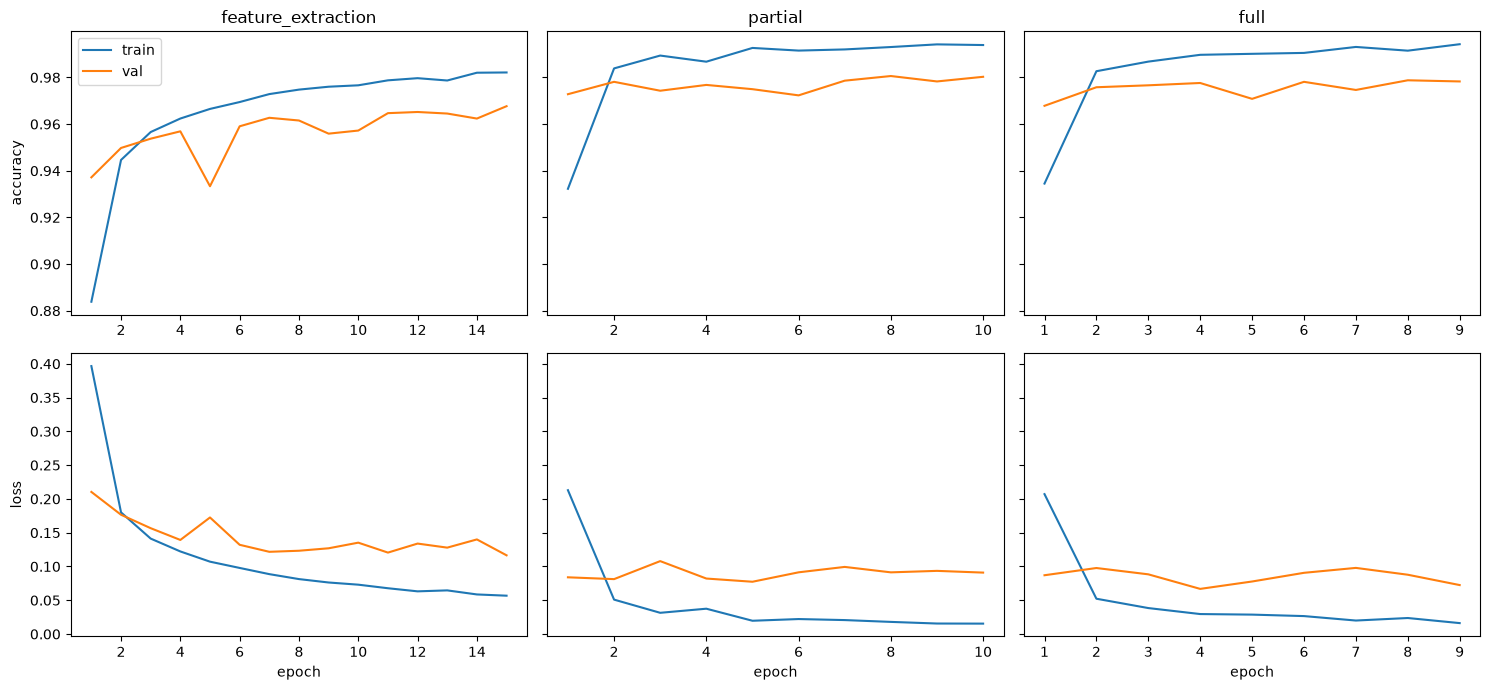

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for j, s in enumerate(STRATEGIES):
    
    h = pd.read_csv(PROJECT_ROOT / "results" / f"{RUN_PREFIX}_{s}" / "history.csv")
    axes[0, j].plot(h.epoch, h.train_acc, label="train"); axes[0, j].plot(h.epoch, h.val_acc, label="val")
    axes[1, j].plot(h.epoch, h.train_loss, label="train"); axes[1, j].plot(h.epoch, h.val_loss, label="val")
    axes[0, j].set_title(s); axes[1, j].set_xlabel("epoch")
    
axes[0, 0].set_ylabel("accuracy"); axes[1, 0].set_ylabel("loss"); axes[0, 0].legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / f"{RUN_PREFIX}_curves.png", dpi=150)
plt.show()

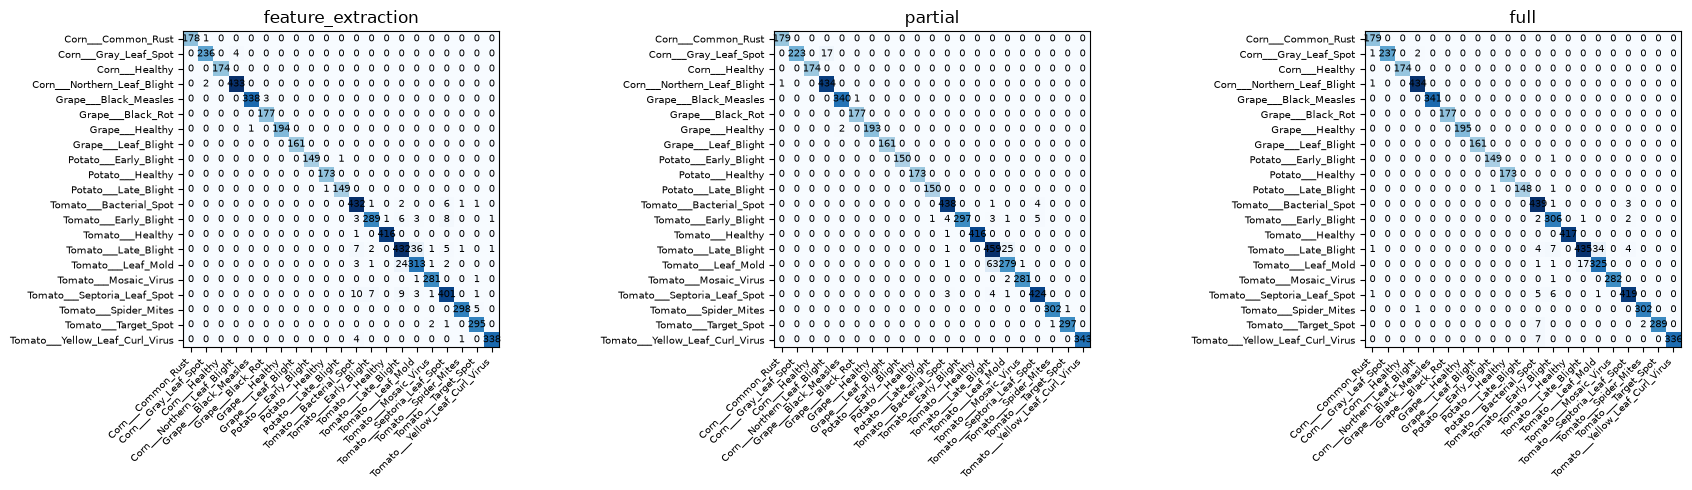

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, s in zip(axes, STRATEGIES):
    
    d = np.load(PROJECT_ROOT / "results" / f"{RUN_PREFIX}_{s}" / "preds.npz")
    cm = confusion_matrix(d["y_true"], d["y_prob"].argmax(1))
    
    ax.imshow(cm, cmap="Blues"); ax.set_title(s)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES, fontsize=7)
    
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=7)
        
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / f"{RUN_PREFIX}_confusion.png", dpi=150)
plt.show()

In [18]:
FIG_DIR = PROJECT_ROOT / "results" / "figures"

with mlflow.start_run(run_name=f"{RUN_PREFIX}_comparison"):
    mlflow.set_tags({"stage": "summary", "model": TIMM_NAME})
    for f in sorted(FIG_DIR.glob(f"{RUN_PREFIX}_*.png")):
        mlflow.log_artifact(str(f), artifact_path="figures")
    mlflow.log_artifact(str(PROJECT_ROOT / "results" / "summary.csv"))